In [1]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn import linear_model
import pandas as pd
import numpy as np
from sklearn.metrics import mean_squared_error
from math import sqrt
df = pd.read_excel("../../clean_coast_data.xlsx")

In [2]:
df= df.loc[df.winter == 1]

In [3]:
# using get_dummies on education column
encoded = pd.get_dummies(df.Area)
# Concatenate the dummies to original dataframe
merged_data = pd.concat([df, encoded], axis=1)
# dropping the original column which was not encoded
merged_data.drop(columns='Area', inplace=True)

In [4]:
merged_data = merged_data.loc[(merged_data['Eilat'] != 1) & (merged_data.year >= 2016)]

In [5]:
merged_data['Date test num'] = merged_data['Date test'].view(np.int64)
without_nulls = merged_data.dropna()

In [6]:
without_nulls.loc[without_nulls.test_result_num > 25,'test_result_num'] = 25

c:\Users\liavc\AppData\Local\Programs\Python\Python39\lib\site-packages\pandas\core\indexing.py:1817: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  self._setitem_single_column(loc, value, pi)


In [7]:
import sys
sys.path.append('../')
import utils
# print(without_nulls.columns)
without_nulls = utils.remove_if_exist(without_nulls)

without_nulls = utils.remove_high_corr(without_nulls)
print(without_nulls.columns)

Index(['city rank', 'bathing_season', 'summer_vaction', 'winter', 'river',
       'military', 'nature', 'Date test', 'test_result', 'year',
       'hifa_port_dis', 'sore_lengh', 'temp avg 3 days', 'have_rained',
       'Center', 'test_result_num'],
      dtype='object')


Quick & Dirty

In [8]:

y = without_nulls[['test_result_num','Date test']]
X = without_nulls.drop(['test_result','test_result_num'],axis=1)

X_train, X_test, y_train, y_test = train_test_split(X, y, shuffle=True, test_size = 0.2)
X_train_scaler = MinMaxScaler()
X_test_scaler = MinMaxScaler()
X_train_scaled = X_train_scaler.fit_transform(X_train.drop('Date test',axis=1))
X_test_scaled = X_test_scaler.fit_transform(X_test.drop('Date test',axis=1))

mlr = linear_model.LinearRegression()
mlr.fit(X_train_scaled,y_train.test_result_num)

prediction = mlr.predict(X_train_scaled)
resTrain =  pd.DataFrame(
    data={
        'Prediction':prediction, 
        'Actual': y_train.test_result_num.values    },
        index=y_train['Date test']
)
prediction = mlr.predict(X_test_scaled)
resTest = pd.DataFrame(
    data={
        'Prediction':prediction,
        'Actual': y_test.test_result_num.values    },
        index=y_test['Date test']
)

print('rmse train',sqrt(mean_squared_error(resTrain.Prediction, resTrain.Actual)))
print('std train',np.std(resTrain.Actual))
print('Sample')
print(resTrain.sample(10))
print()

print('rmse test',sqrt(mean_squared_error(resTest.Prediction, resTest.Actual)))
print('std test',np.std(resTest.Actual))
print('Sample')
print(resTest.sample(10))
print()

rmse train 4.394755597138895
std train 4.627746477938004
Sample
            Prediction  Actual
Date test                     
2021-12-31    4.073609    4.80
2016-02-09    7.840626   19.47
2018-12-11    5.082541    4.70
2016-02-09    6.934761    5.03
2022-01-15    2.814321    2.00
2017-12-18    2.794019    3.60
2017-01-25    6.456993   10.84
2016-12-27    6.046638   25.00
2020-12-30    3.347619    0.30
2021-12-31    4.607838    8.37

rmse test 4.553057957613876
std test 4.844599491952196
Sample
            Prediction  Actual
Date test                     
2017-12-30    5.405203    3.78
2021-01-14    3.838701    3.73
2018-12-25    4.933238    0.60
2017-12-30    5.221332    0.80
2019-02-05    4.234101    2.20
2022-01-15    4.601964    5.81
2019-02-05    2.875293    1.05
2017-12-18    3.932734    1.60
2022-02-15    5.441271   15.09
2022-12-15    1.882168    0.50



with univariant feature selection

In [9]:
from sklearn.feature_selection import SelectKBest
from sklearn.feature_selection import f_regression
from sklearn.metrics import r2_score

stds_train = list()
rmses_train = list()
r2s_train = list()

stds_test = list()
rmses_test = list()
r2s_test = list()

X = without_nulls.drop(['Date test','test_result','test_result_num'],axis=1)
y= without_nulls['test_result_num']

f_reg_selector = SelectKBest(f_regression, k=9)
f_reg_selector.fit(X, y)
f_reg_support = f_reg_selector.get_support()
f_reg_feature = X.loc[:,f_reg_support].columns.to_list()

uniX = X.loc[:,f_reg_support]
# 
for i in range(100):
    X_train, X_test, y_train, y_test = train_test_split(uniX, y, shuffle=True, test_size = 0.3)
    X_train_scaler = MinMaxScaler()
    X_test_scaler = MinMaxScaler()
    X_train_scaled = X_train_scaler.fit_transform(X_train)
    X_test_scaled = X_test_scaler.fit_transform(X_test)

    mlr = linear_model.LinearRegression()
    mlr.fit(X_train_scaled,y_train)

    prediction = mlr.predict(X_train_scaled)
    resTrain =  pd.DataFrame(
        data={
            'Prediction':prediction, 
            'Actual': y_train.values    },
    )
    prediction = mlr.predict(X_test_scaled)
    resTest = pd.DataFrame(
        data={
            'Prediction':prediction,
            'Actual': y_test.values    },
    )
    train_rmse = sqrt(mean_squared_error(resTrain.Prediction, resTrain.Actual))
    train_std = np.std(resTrain.Actual)
    train_r2 = r2_score(resTrain.Actual, resTrain.Prediction)
    test_rmse = sqrt(mean_squared_error(resTest.Prediction, resTest.Actual))
    test_std = np.std(resTest.Actual)
    test_r2 = r2_score(resTest.Actual, resTest.Prediction)
    stds_train.append(train_std)
    rmses_train.append(train_rmse)
    r2s_train.append(train_r2)
    stds_test.append(test_std)
    rmses_test.append(test_rmse)
    r2s_test.append(test_r2)

print("train std: ",np.mean(stds_train))
print("train rmse: ",np.mean(rmses_train))
print("train r2: ",np.mean(r2s_train))
print()
print("test std: ",np.mean(stds_test))
print("test rmse: ",np.mean(rmses_test))
print("test r2: ",np.mean(r2s_test))

train std:  4.677726760925169
train rmse:  4.4236638111967475
train r2:  0.1056128682313028

test std:  4.648613139258472
test rmse:  4.443957904432911
test r2:  0.08563756139355409


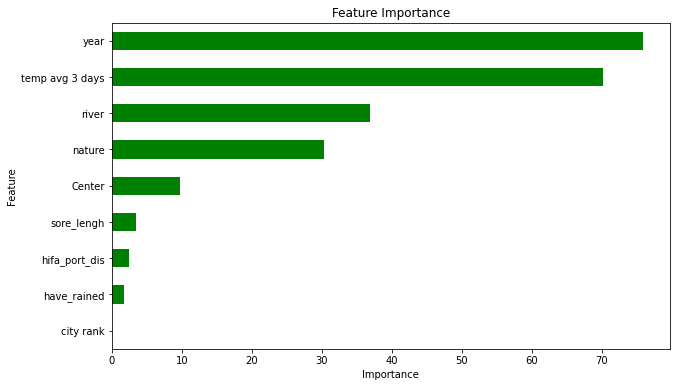

In [10]:
scores = pd.Series(f_reg_selector.scores_.tolist()) 
p_values = pd.Series(f_reg_selector.pvalues_.tolist()) 
selected_df = pd.DataFrame({'univariate_score':scores, 'p_values':p_values})
selected_df.set_index(X.columns, inplace=True, drop=True)
univariate = selected_df.sort_values(by='univariate_score', ascending=False)

univariate = univariate.loc[univariate.index.isin(f_reg_feature)]
from matplotlib import pyplot as plt

plt.figure(figsize=(10,6))
global_importances = pd.Series(univariate['univariate_score'], index=list(univariate.index))
global_importances.sort_values(ascending=True, inplace=True)
global_importances.plot.barh(color='green')
plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Feature Importance")
plt.show()

[(-4.43037, 'temp avg 3 days'), (-2.27899, 'year'), (-2.17759, 'nature'), (-1.58248, 'sore_lengh'), (-0.98674, 'Center'), (-0.55518, 'hifa_port_dis'), (0.39879, 'have_rained'), (1.21113, 'river'), (1.23992, 'city rank')]


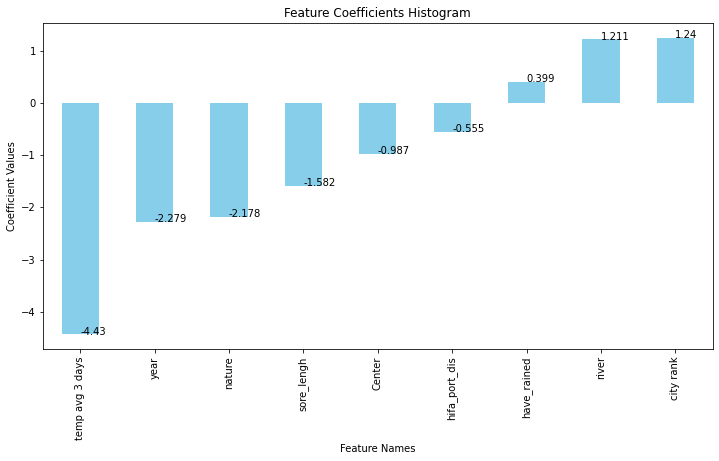

In [11]:
#find coeff based on all examples

X_scaler = MinMaxScaler()
X_scaled = X_scaler.fit_transform(uniX)

mlr = linear_model.LinearRegression()
mlr.fit(X_scaled,y)

coef = sorted( list(zip(np.round(mlr.coef_,5),uniX.columns)))
print(coef)
d = {}
for tup in coef:
    d[tup[-1]] = tup[0]
coefDF = pd.DataFrame.from_dict(d,orient='index')
coefDF.columns = ['coeff']

import pandas as pd
import matplotlib.pyplot as plt

# Assuming df is your DataFrame with a 'coeff' column

# Plotting a histogram
coefDF.columns = ['coeff']
coefDF['coeff'].plot(kind='bar', figsize=(12, 6), color='skyblue')
plt.xlabel('Feature Names')
plt.ylabel('Coefficient Values')
plt.title('Feature Coefficients Histogram')

# Displaying the row names (index) on top of each bar
for i, value in enumerate(coefDF['coeff']):
    plt.text(i, value, str(round(value,3)))

plt.show()
